In [1]:
import sys
print("Python:", sys.executable)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("pandas:", pd.__version__)
print("CWD:", Path.cwd())

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW = ROOT / "data" / "raw" / "data.csv"
print("ROOT:", ROOT)
print("CSV existe:", DATA_RAW.exists())

Python: c:\PROYECTOS\capstone-dropout\dropout-env\Scripts\python.exe
pandas: 3.0.6
CWD: c:\PROYECTOS\capstone-dropout\notebooks
ROOT: c:\PROYECTOS\capstone-dropout
CSV existe: True


In [2]:
df = pd.read_csv(DATA_RAW, sep=";")
df.columns = df.columns.str.strip().str.replace("\t", "", regex=False)
print("Shape:", df.shape)
print("Columnas:")
for i, c in enumerate(df.columns, 1):
    print(f"{i:2d}. {c}")

Shape: (4424, 37)
Columnas:
 1. Marital status
 2. Application mode
 3. Application order
 4. Course
 5. Daytime/evening attendance
 6. Previous qualification
 7. Previous qualification (grade)
 8. Nacionality
 9. Mother's qualification
10. Father's qualification
11. Mother's occupation
12. Father's occupation
13. Admission grade
14. Displaced
15. Educational special needs
16. Debtor
17. Tuition fees up to date
18. Gender
19. Scholarship holder
20. Age at enrollment
21. International
22. Curricular units 1st sem (credited)
23. Curricular units 1st sem (enrolled)
24. Curricular units 1st sem (evaluations)
25. Curricular units 1st sem (approved)
26. Curricular units 1st sem (grade)
27. Curricular units 1st sem (without evaluations)
28. Curricular units 2nd sem (credited)
29. Curricular units 2nd sem (enrolled)
30. Curricular units 2nd sem (evaluations)
31. Curricular units 2nd sem (approved)
32. Curricular units 2nd sem (grade)
33. Curricular units 2nd sem (without evaluations)
34. Unemp

In [3]:
map_marital = {1:"Single",2:"Married",3:"Widower",4:"Divorced",5:"Facto union",6:"Legally separated"}
map_attendance = {1:"Daytime",0:"Evening"}
map_gender = {1:"Male",0:"Female"}
map_yesno = {1:"Yes",0:"No"}
map_course = {
    33:"Biofuel Tech",171:"Animation & Multimedia",8014:"Social Service (eve)",
    9003:"Agronomy",9070:"Comm. Design",9085:"Vet Nursing",9119:"Informatics Eng",
    9130:"Equinculture",9147:"Management",9238:"Social Service",9254:"Tourism",
    9500:"Nursing",9556:"Oral Hygiene",9670:"Advertising & Marketing",
    9773:"Journalism & Comm",9853:"Basic Education",9991:"Management (eve)"
}
df["Target"] = df["Target"].astype(str).str.strip()
df["Marital status"] = df["Marital status"].map(map_marital)
df["Daytime/evening attendance"] = df["Daytime/evening attendance"].map(map_attendance)
df["Gender"] = df["Gender"].map(map_gender)
for col in ["Displaced","Educational special needs","Debtor",
            "Tuition fees up to date","Scholarship holder","International"]:
    df[col] = df[col].map(map_yesno)
df["Course"] = df["Course"].map(map_course)
print(df[["Marital status","Daytime/evening attendance","Gender","Course"]].head())

  Marital status Daytime/evening attendance  Gender                  Course
0         Single                    Daytime    Male  Animation & Multimedia
1         Single                    Daytime    Male                 Tourism
2         Single                    Daytime    Male            Comm. Design
3         Single                    Daytime  Female       Journalism & Comm
4        Married                    Evening  Female    Social Service (eve)


In [4]:
df["target_bin"] = (df["Target"] == "Dropout").astype(int)
print("Distribución original:")
print(df["Target"].value_counts())
print(f"\nBalance binario: {df['target_bin'].mean():.1%} Dropout")

Distribución original:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Balance binario: 32.1% Dropout


In [5]:
print("Faltantes por columna (top):")
print(df.isna().sum().sort_values(ascending=False).head(10))
print("\nTotal faltantes:", df.isna().sum().sum())
print("Duplicados:", df.duplicated().sum())

Faltantes por columna (top):
Marital status                    0
Application mode                  0
Application order                 0
Course                            0
Daytime/evening attendance        0
Previous qualification            0
Previous qualification (grade)    0
Nacionality                       0
Mother's qualification            0
Father's qualification            0
dtype: int64

Total faltantes: 0
Duplicados: 0


In [6]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Application mode,4424.0,18.67,17.48,1.00,1.00,17.00,39.00,57.00
Application order,4424.0,1.73,1.31,0.00,1.00,1.00,2.00,9.00
Previous qualification,4424.0,4.58,10.22,1.00,1.00,1.00,1.00,43.00
Previous qualification (grade),4424.0,132.61,13.19,95.00,125.00,133.10,140.00,190.00
Nacionality,4424.0,1.87,6.91,1.00,1.00,1.00,1.00,109.00
Mother's qualification,4424.0,19.56,15.60,1.00,2.00,19.00,37.00,44.00
Father's qualification,4424.0,22.28,15.34,1.00,3.00,19.00,37.00,44.00
Mother's occupation,4424.0,10.96,26.42,0.00,4.00,5.00,9.00,194.00
Father's occupation,4424.0,11.03,25.26,0.00,4.00,7.00,9.00,195.00
Admission grade,4424.0,126.98,14.48,95.00,117.90,126.10,134.80,190.00


In [14]:
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports" / "figures"
REPORTS.mkdir(parents=True, exist_ok=True)

print("REPORTS definido en:", REPORTS)

REPORTS definido en: c:\PROYECTOS\capstone-dropout\reports\figures


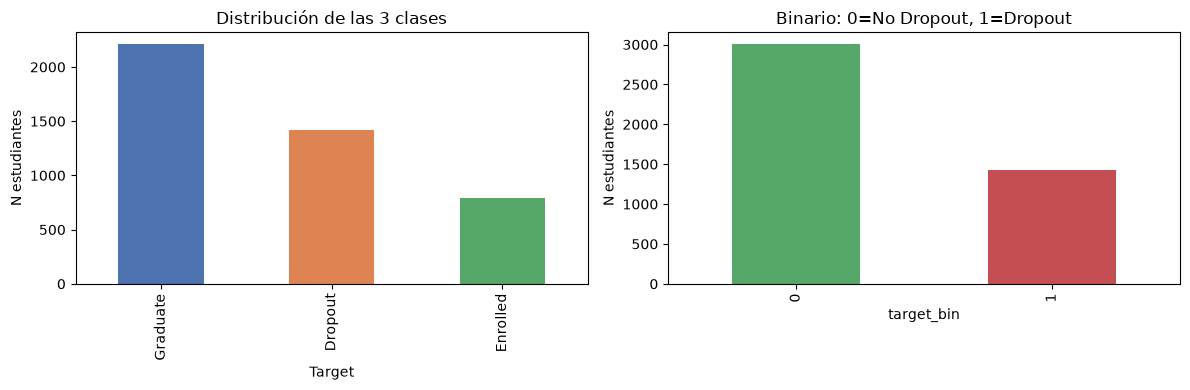

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["Target"].value_counts().plot(kind="bar", ax=axes[0], color=["#4C72B0","#DD8452","#55A868"])
axes[0].set_title("Distribución de las 3 clases")
axes[0].set_ylabel("N estudiantes")
df["target_bin"].value_counts().plot(kind="bar", ax=axes[1], color=["#55A868","#C44E52"])
axes[1].set_title("Binario: 0=No Dropout, 1=Dropout")
axes[1].set_ylabel("N estudiantes")
plt.tight_layout()
plt.savefig(REPORTS / "01_target_distribution.png", dpi=120)
plt.show()

                         mean  count
Course                              
Biofuel Tech             66.7     12
Equinculture             55.3    141
Informatics Eng          54.1    170
Management (eve)         50.7    268
Basic Education          44.3    192
Agronomy                 41.0    210
Oral Hygiene             38.4     86
Animation & Multimedia   38.1    215
Tourism                  38.1    252
Advertising & Marketing  35.4    268
Management               35.3    380
Social Service (eve)     33.0    215
Journalism & Comm        30.5    331
Vet Nursing              26.7    337
Comm. Design             22.6    226
Social Service           18.3    355
Nursing                  15.4    766


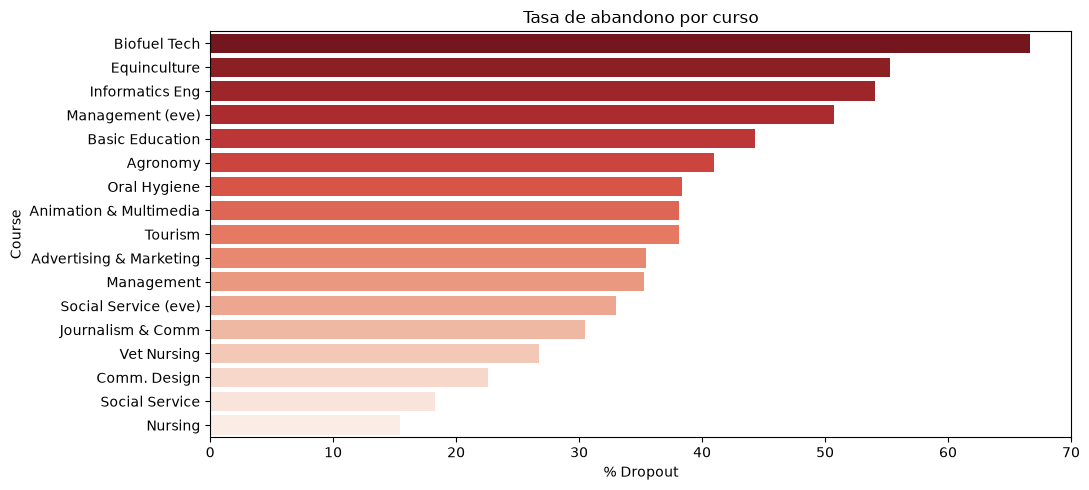

In [16]:
curso_risk = df.groupby("Course")["target_bin"].agg(["mean","count"]).sort_values("mean", ascending=False)
curso_risk["mean"] = (curso_risk["mean"]*100).round(1)
print(curso_risk)
plt.figure(figsize=(11,5))
sns.barplot(data=curso_risk.reset_index(), x="mean", y="Course", hue="Course", palette="Reds_r", legend=False)
plt.xlabel("% Dropout")
plt.title("Tasa de abandono por curso")
plt.tight_layout()
plt.savefig(REPORTS / "02_dropout_por_curso.png", dpi=120)
plt.show()

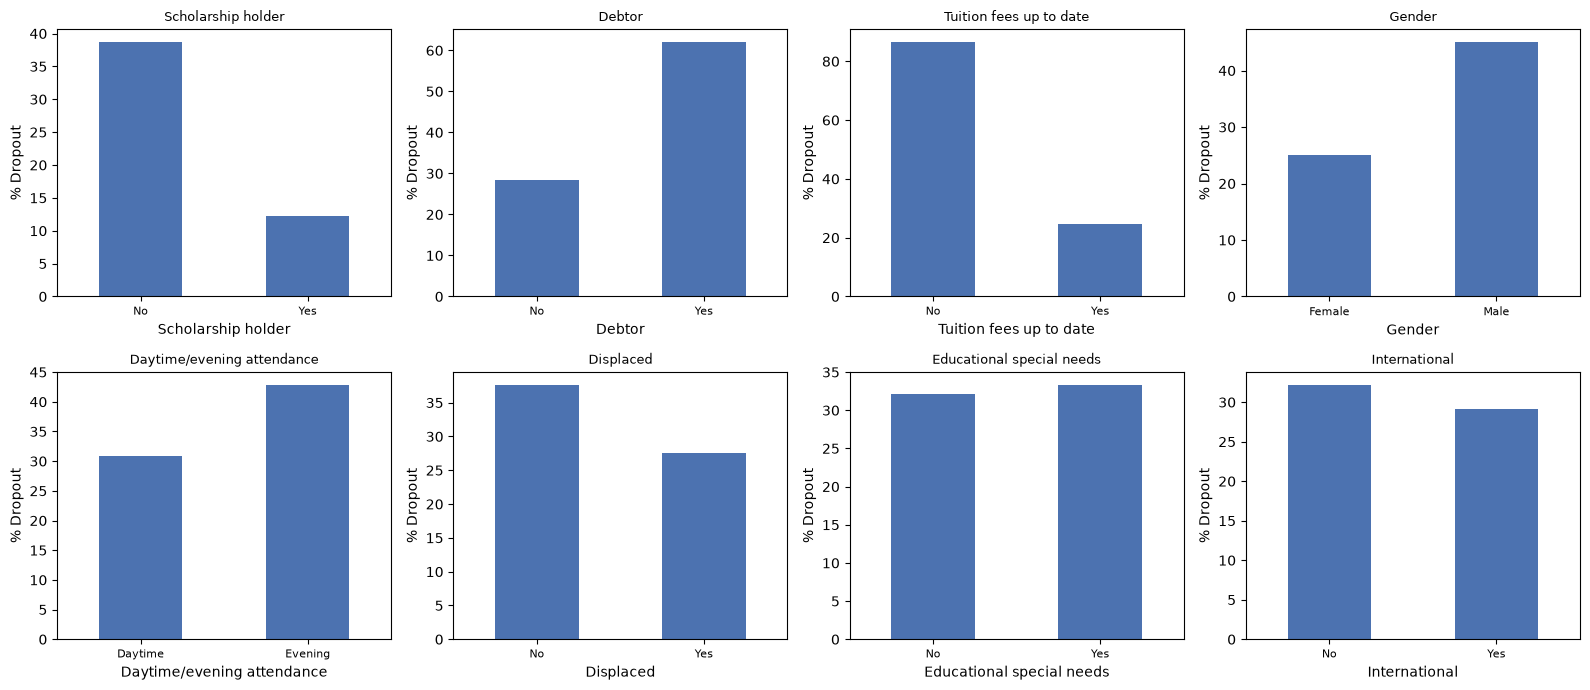

In [17]:
factores = ["Scholarship holder","Debtor","Tuition fees up to date",
            "Gender","Daytime/evening attendance","Displaced",
            "Educational special needs","International"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, factores):
    rate = df.groupby(col)["target_bin"].mean() * 100
    rate.plot(kind="bar", ax=ax, color="#4C72B0")
    ax.set_title(col, fontsize=9)
    ax.set_ylabel("% Dropout")
    ax.tick_params(axis="x", rotation=0, labelsize=8)
plt.tight_layout()
plt.savefig(REPORTS / "03_factores_binarios.png", dpi=120)
plt.show()

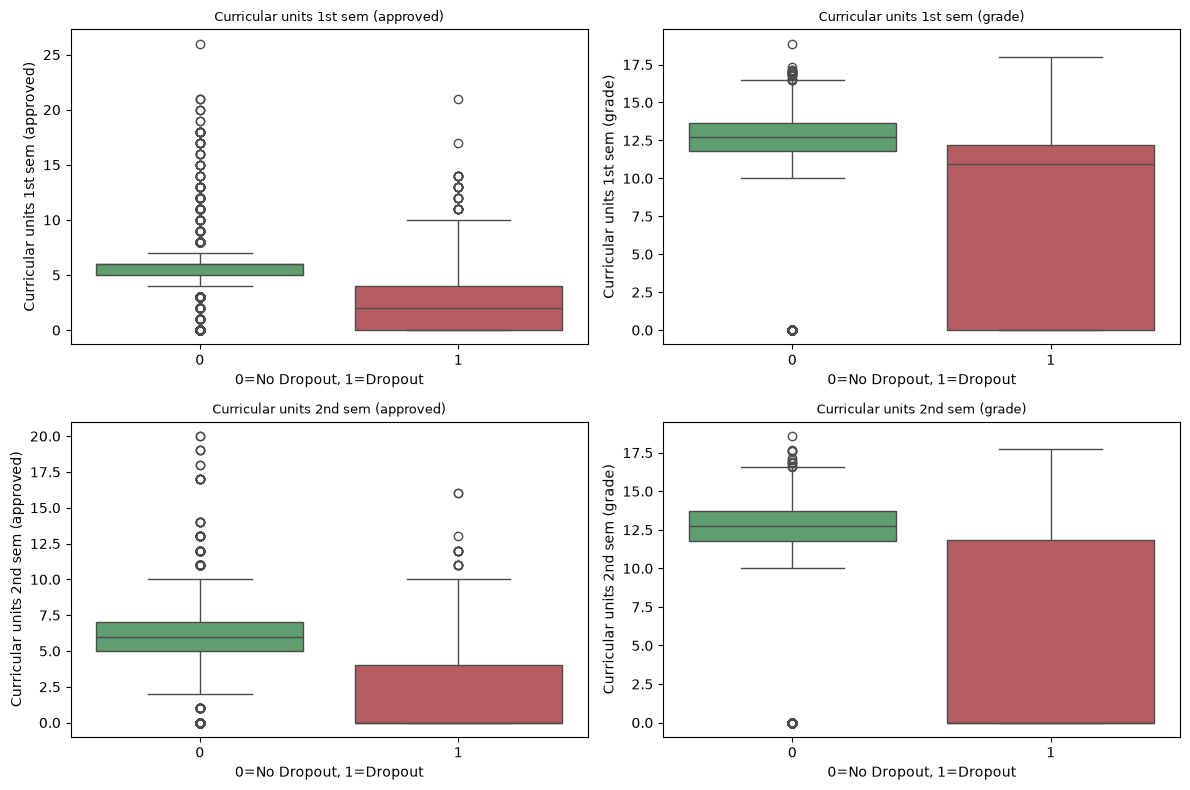

In [18]:
notas = ["Curricular units 1st sem (approved)","Curricular units 1st sem (grade)",
         "Curricular units 2nd sem (approved)","Curricular units 2nd sem (grade)"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, notas):
    sns.boxplot(data=df, x="target_bin", y=col, ax=ax, hue="target_bin", palette=["#55A868","#C44E52"], legend=False)
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("0=No Dropout, 1=Dropout")
plt.tight_layout()
plt.savefig(REPORTS / "04_notas_vs_dropout.png", dpi=120)
plt.show()

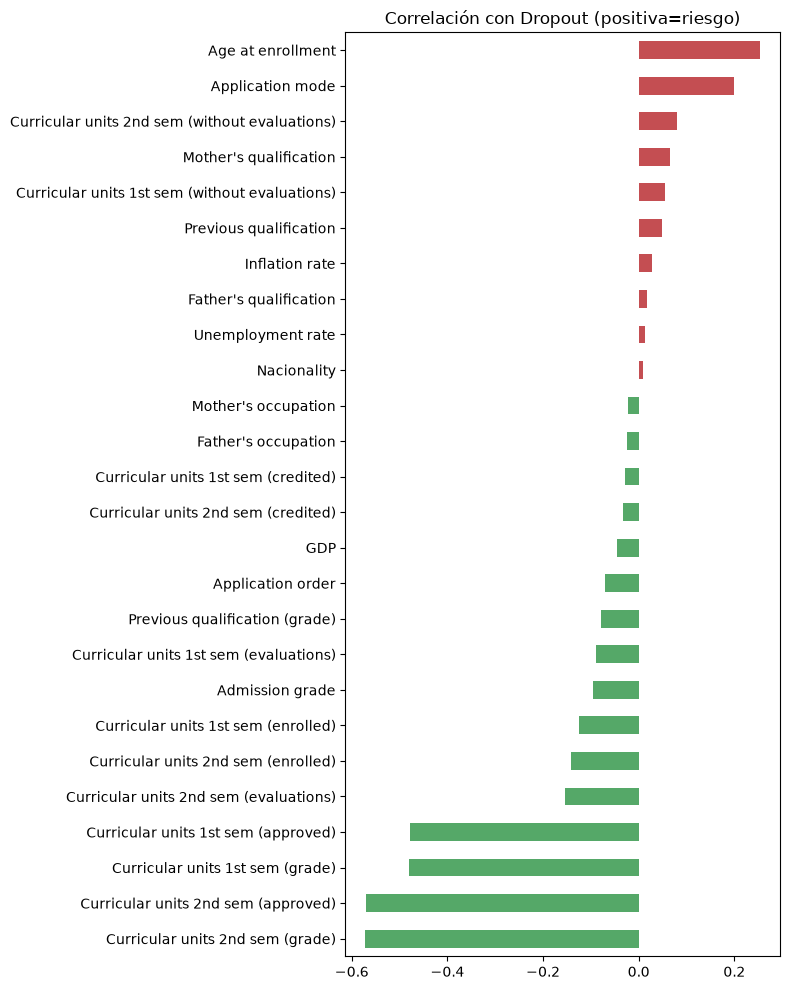

In [19]:
corr = df.select_dtypes(include=[np.number]).corr()["target_bin"].drop("target_bin").sort_values()
plt.figure(figsize=(8, 10))
corr.plot(kind="barh", color=np.where(corr>0, "#C44E52", "#55A868"))
plt.title("Correlación con Dropout (positiva=riesgo)")
plt.tight_layout()
plt.savefig(REPORTS / "05_correlaciones.png", dpi=120)
plt.show()

In [12]:
from sklearn.model_selection import train_test_split
df.to_csv(ROOT / "data" / "processed" / "data_clean.csv", index=False)
X = df.drop(columns=["Target","target_bin"])
y = df["target_bin"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Dropout en train: {y_train.mean():.1%}")
print(f"Dropout en test:  {y_test.mean():.1%}")

Train: (3539, 36), Test: (885, 36)
Dropout en train: 32.1%
Dropout en test:  32.1%


In [13]:
print("=== RESUMEN EDA ===")
print(f"Estudiantes totales: {len(df)}")
print(f"Dropout: {df['target_bin'].sum()} ({df['target_bin'].mean():.1%})")
print(f"Features: {X.shape[1]}")
print(f"Curso con mayor riesgo: {curso_risk.index[0]} ({curso_risk['mean'].iloc[0]}%)")
print(f"Curso con menor riesgo: {curso_risk.index[-1]} ({curso_risk['mean'].iloc[-1]}%)")

=== RESUMEN EDA ===
Estudiantes totales: 4424
Dropout: 1421 (32.1%)
Features: 36
Curso con mayor riesgo: Biofuel Tech (66.7%)
Curso con menor riesgo: Nursing (15.4%)
